# Prototype 23 — Jev collection auto-assignment (Phase 3 demo)

**What this shows.** For every saved outfit + every target collection, a batched Jev-Noul call (`does this outfit belong in collection X?`) with calibrated confidence. Real DB, real item images. Metrics: latency, cost, confidence distribution, coverage. No Gemini calls at demo time — item metadata is read straight from the DB.

**Why now.** Phase 1 (suggest ranking) + Phase 0.5 (self-hosted benchmark) already have prototypes. Phase 3 is greenfield — this notebook is the first look at whether Jev-Noul is sharp enough on collection-fit to power a real user-facing feature, and it seeds the Phase 3 architecture write-up.

**Data reality check.** The local DB has 2 existing collections named `test` / `Test 1` — synthetic, no meaningful ground truth. This notebook defines **4 target collections** that a real user might make (Fall Layers, Workwear Rotation, Cold Weather, Weekend Casual) and runs Jev against those. Existing assignments are surfaced separately for cross-reference, not treated as ground truth.

**Non-scope.** No code changes to `src/`. No wallet wiring. No route changes. No Gemini re-categorization. Follow-up architecture issue captures those.

## 1. Setup — imports, env, paths

In [1]:
from __future__ import annotations

import base64
import io
import json
import os
import sqlite3
import statistics
import sys
import time
from pathlib import Path

import pandas as pd
from IPython.display import HTML, display

REPO_ROOT = Path.cwd().parent.parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Load .env (same convention as nb20/21)
for env_path in (REPO_ROOT / ".env", REPO_ROOT / "prototypes" / ".env"):
    if env_path.exists():
        for line in env_path.read_text().splitlines():
            line = line.strip()
            if not line or line.startswith("#") or "=" not in line:
                continue
            k, v = line.split("=", 1)
            os.environ.setdefault(k.strip(), v.strip().strip('"').strip("'"))

CLOSET_DATA_DIR = Path(os.environ.get("CLOSET_DATA_DIR", str(REPO_ROOT / ".closet")))
if not (CLOSET_DATA_DIR / "closet.db").exists():
    # fallback for home-dir install
    CLOSET_DATA_DIR = Path.home() / ".closet"
CLOSET_DB = CLOSET_DATA_DIR / "closet.db"
IMAGES_ROOT = CLOSET_DATA_DIR
OUT_DIR = REPO_ROOT / "prototypes" / "outputs" / "23"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"CLOSET_DATA_DIR: {CLOSET_DATA_DIR}")
print(f"CLOSET_DB:       {CLOSET_DB}  exists={CLOSET_DB.exists()}")
print(f"IMAGES_ROOT:     {IMAGES_ROOT}")
print(f"OUT_DIR:         {OUT_DIR}")
print(f"OPENROUTER_API_KEY set: {bool(os.environ.get('OPENROUTER_API_KEY'))}")

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


CLOSET_DATA_DIR: .closet
CLOSET_DB:       .closet/closet.db  exists=True
IMAGES_ROOT:     .closet
OUT_DIR:         prototypes/outputs/23
OPENROUTER_API_KEY set: True


## 2. Jev client — OpenRouter `/api/alpha/decisions` (copied from nb20)

In [2]:
import urllib.request
import urllib.error

JEV_MODEL = "typesafe/jev-1.13"
DECISIONS_URL = "https://openrouter.ai/api/alpha/decisions"


def call_jev_decisions(state: str, questions: dict, *, timeout_s: int = 60) -> dict:
    """POST to OpenRouter's decisions endpoint. Returns a dict with
    {ok, latency_s, model, answers, usage, error?}. Same shape as nb20 for
    consistent metrics + logging."""
    api_key = os.environ.get("OPENROUTER_API_KEY", "")
    if not api_key:
        return {"ok": False, "error": "OPENROUTER_API_KEY not set"}
    body = json.dumps({"model": JEV_MODEL, "state": state, "questions": questions}).encode()
    req = urllib.request.Request(
        DECISIONS_URL,
        data=body,
        method="POST",
        headers={"Authorization": f"Bearer {api_key}", "Content-Type": "application/json"},
    )
    t0 = time.perf_counter()
    try:
        with urllib.request.urlopen(req, timeout=timeout_s) as resp:
            payload = json.loads(resp.read())
        return {
            "ok": True,
            "latency_s": time.perf_counter() - t0,
            "model": payload.get("model"),
            "answers": payload.get("answers") or {},
            "usage": payload.get("usage") or {},
            "id": payload.get("id"),
            "provider": payload.get("provider"),
        }
    except urllib.error.HTTPError as e:
        return {"ok": False, "latency_s": time.perf_counter() - t0,
                "error": f"HTTP {e.code}: {e.read()[:300].decode(errors='replace')}"}
    except Exception as e:
        return {"ok": False, "latency_s": time.perf_counter() - t0,
                "error": f"{type(e).__name__}: {e}"}


probe = call_jev_decisions(
    state="An outfit consisting of: wool overcoat, cashmere sweater, wool trousers, leather brogues.",
    questions={
        "fits_workwear": {"type": "noul", "instructions": "Does this outfit fit a formal workwear collection?"},
    },
)
print(json.dumps(probe, indent=2, default=str))

{
  "ok": true,
  "latency_s": 0.5576540830079466,
  "model": "typesafe/jev-1.13-20260917",
  "answers": {
    "fits_workwear": {
      "type": "noul",
      "noul": 0.67
    }
  },
  "usage": {
    "input_tokens": 298,
    "output_tokens": 24,
    "cost": 1.2516e-05
  },
  "id": "gen-dec-1790183901-3DlTjCA4dXyLiG8HEEa0",
  "provider": "TypeSafe"
}


## 3. Data loaders — items, outfits, existing collections

In [3]:
def _decode_json_fields(row: dict, fields: tuple[str, ...]) -> dict:
    for f in fields:
        try:
            row[f] = json.loads(row[f]) if row[f] else []
        except (json.JSONDecodeError, TypeError):
            row[f] = []
    return row


def load_all(db_path: Path, user_id: str = "self"):
    con = sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)
    con.row_factory = sqlite3.Row
    items = [dict(r) for r in con.execute(
        """SELECT id, category, subcategory, primary_color, colors, brand, material,
                  season, occasion, tags, ai_description, image_uri, wear_context
           FROM items WHERE user_id = ? ORDER BY id""",
        (user_id,)).fetchall()]
    outfits = [dict(r) for r in con.execute(
        """SELECT id, name, item_ids, occasion, season, tags, notes, ai_description, cover_image_uri
           FROM outfits WHERE user_id = ? ORDER BY name""",
        (user_id,)).fetchall()]
    collections = [dict(r) for r in con.execute(
        """SELECT id, name, description, tags, season, cover_image_uri
           FROM collections WHERE user_id = ? ORDER BY name""",
        (user_id,)).fetchall()]
    existing_assignments = [dict(r) for r in con.execute(
        """SELECT co.collection_id, co.outfit_id, c.name AS collection_name, o.name AS outfit_name
           FROM collection_outfits co
           JOIN collections c ON co.collection_id = c.id
           JOIN outfits o ON co.outfit_id = o.id
           WHERE c.user_id = ? AND o.user_id = ?""",
        (user_id, user_id)).fetchall()]
    con.close()

    for it in items:
        _decode_json_fields(it, ("colors", "season", "occasion", "tags"))
    for o in outfits:
        _decode_json_fields(o, ("item_ids", "season", "tags"))
    for c in collections:
        _decode_json_fields(c, ("season", "tags"))
    return items, outfits, collections, existing_assignments


items, outfits, collections, existing_assignments = load_all(CLOSET_DB, user_id="self")
items_by_id = {it["id"]: it for it in items}

print(f"Items:        {len(items)}")
print(f"Outfits:      {len(outfits)}")
print(f"Collections:  {len(collections)}  (names: {[c['name'] for c in collections]})")
print(f"Existing assignments: {len(existing_assignments)}")
for ea in existing_assignments:
    print(f"  {ea['collection_name']!r:12} <- {ea['outfit_name']!r}")

Items:        41
Outfits:      32
Collections:  2  (names: ['Test 1', 'test'])
Existing assignments: 8
  'test'       <- 'Cool Weather Casual'
  'test'       <- 'Black and red'
  'test'       <- 'Sophisticated Professional'
  'test'       <- 'Test'
  'test'       <- 'Sophisticated Professional'
  'Test 1'     <- 'The Eccentric Urbanite'
  'Test 1'     <- 'Cozy Winter Rugged'
  'Test 1'     <- 'The Disjointed Academic'


## 4. Rendering helpers — real product images inline

The DB stores `image_uri` as `images/items/<id>.jpg`. Files live under `CLOSET_DATA_DIR/`. We read the bytes, downscale to a thumbnail via PIL if it's available, and embed as `data:` URLs so the notebook is self-contained (no local web server needed).


HAVE_PIL: True



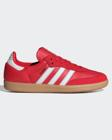
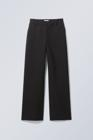
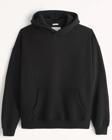
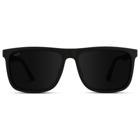

In [4]:
try:
    from PIL import Image
    HAVE_PIL = True
except ImportError:
    HAVE_PIL = False
print(f"HAVE_PIL: {HAVE_PIL}")

_IMG_CACHE: dict[str, str] = {}


def image_data_url(image_uri: str | None, *, max_dim: int = 140) -> str:
    """Return `data:image/jpeg;base64,...` for `image_uri` (relative to CLOSET_DATA_DIR).
    Downscales via PIL when available. Returns '' when the file is missing."""
    if not image_uri:
        return ""
    if image_uri in _IMG_CACHE:
        return _IMG_CACHE[image_uri]
    abs_path = IMAGES_ROOT / image_uri
    if not abs_path.exists():
        _IMG_CACHE[image_uri] = ""
        return ""
    raw = abs_path.read_bytes()
    if HAVE_PIL:
        try:
            img = Image.open(io.BytesIO(raw))
            img.thumbnail((max_dim, max_dim))
            buf = io.BytesIO()
            img.convert("RGB").save(buf, format="JPEG", quality=75)
            raw = buf.getvalue()
        except Exception:
            pass  # fall back to raw bytes
    b64 = base64.b64encode(raw).decode()
    url = f"data:image/jpeg;base64,{b64}"
    _IMG_CACHE[image_uri] = url
    return url


def outfit_image_html(outfit: dict, *, max_items: int = 6) -> str:
    cells = []
    for iid in outfit.get("item_ids", [])[:max_items]:
        it = items_by_id.get(iid)
        if not it:
            continue
        url = image_data_url(it.get("image_uri"))
        if not url:
            continue
        cells.append(
            f"<img src='{url}' style='height:72px;width:72px;object-fit:cover;"
            f"border:1px solid #ddd;border-radius:6px;margin:2px'/>"
        )
    return "<div style='display:flex;flex-wrap:wrap'>" + "".join(cells) + "</div>"


# Sanity check: render the first outfit's items
sample_outfit = outfits[0]
display(HTML(f"<b>{sample_outfit['name']}</b>" + outfit_image_html(sample_outfit)))

## 5. Target collections — synthesized, not the DB's "test" ones

Real user closets will have meaningful collections. These four are hand-authored to match the closet's actual composition (workwear-heavy + several outdoor/casual outfits + winter emphasis). Assignments Jev finds should match the outfit names intuitively.


In [5]:
TARGET_COLLECTIONS = [
    {
        "key": "workwear_rotation",
        "name": "Workwear Rotation",
        "description": (
            "Office-appropriate outfits for a professional workplace. Polished, put-together, "
            "tailored pieces. Includes blazers, dress shirts, structured trousers, and dress shoes. "
            "Excludes athleisure, streetwear, and weekend-casual looks."
        ),
    },
    {
        "key": "cold_weather",
        "name": "Cold Weather",
        "description": (
            "Outfits that keep you warm in winter or late fall — heavy coats, wool layers, sweaters, "
            "thermal fabrics, boots. Excludes lightweight or summer-only pieces."
        ),
    },
    {
        "key": "weekend_casual",
        "name": "Weekend Casual",
        "description": (
            "Relaxed outfits for weekends and errands. Comfortable, low-effort, includes jeans, "
            "t-shirts, hoodies, sneakers. Excludes formal, business, or dressy pieces."
        ),
    },
    {
        "key": "outdoor_rugged",
        "name": "Outdoor Rugged",
        "description": (
            "Outfits built for the outdoors — hiking, walking, active use. Utility jackets, "
            "work boots, sturdy fabrics, layered warmth. Excludes formal, dressy, or delicate pieces."
        ),
    },
]

print(f"{len(TARGET_COLLECTIONS)} target collections defined")
for c in TARGET_COLLECTIONS:
    print(f"  {c['name']:20}  {c['description'][:90]}...")

4 target collections defined
  Workwear Rotation     Office-appropriate outfits for a professional workplace. Polished, put-together, tailored ...
  Cold Weather          Outfits that keep you warm in winter or late fall — heavy coats, wool layers, sweaters, th...
  Weekend Casual        Relaxed outfits for weekends and errands. Comfortable, low-effort, includes jeans, t-shirt...
  Outdoor Rugged        Outfits built for the outdoors — hiking, walking, active use. Utility jackets, work boots,...


## 6. Serialize outfits — compact text descriptor per outfit

Everything Jev sees comes from the DB — no re-categorization, no new Gemini calls.


In [6]:
def item_descriptor(it: dict) -> str:
    parts: list[str] = []
    cat = it.get("category") or "item"
    sub = it.get("subcategory")
    parts.append(f"{cat}:{sub}" if sub else cat)
    colors = it.get("colors") or ([it["primary_color"]] if it.get("primary_color") else [])
    if colors:
        parts.append("/".join(str(c) for c in colors[:2]))
    if it.get("material"):
        parts.append(str(it["material"]))
    if it.get("brand"):
        parts.append(f"({it['brand']})")
    return " ".join(parts)


def outfit_descriptor(o: dict) -> str:
    lines: list[str] = []
    lines.append(f"Name: {o.get('name') or 'Unnamed'}")
    if o.get("occasion"):
        lines.append(f"Occasion: {o['occasion']}")
    if o.get("season"):
        lines.append(f"Season: {', '.join(o['season'])}")
    if o.get("tags"):
        lines.append(f"Tags: {', '.join(o['tags'])}")
    it_lines = []
    for iid in o.get("item_ids", []):
        it = items_by_id.get(iid)
        if it:
            it_lines.append(f"  - {item_descriptor(it)}")
    if it_lines:
        lines.append("Items:")
        lines.extend(it_lines)
    if o.get("ai_description"):
        lines.append(f"Description: {o['ai_description']}")
    return "\n".join(lines)


print(outfit_descriptor(outfits[0]))
print("---")
print(outfit_descriptor(outfits[3]))

Name: Black and red
Season: fall
Tags: funkytowm
Items:
  - shoes:sneakers red/white
  - bottoms:wide-leg pants black
  - tops:hoodie black
  - accessories:sunglasses black
---
Name: Classic Cold-Weather Professional
Occasion: work
Items:
  - tops:button-down shirt navy blue
  - bottoms:trousers tan
  - outerwear:trench coat tan
  - shoes:sneakers white/blue
  - accessories:scarf off-white/maroon


## 7. Run Jev — one batched call per collection, N Nouls per outfit

**Batching choice.** State = the collection definition. Questions = one Noul per outfit (`"outfit_<id>"`). This is 1 HTTP call per collection = **4 calls total** for 4 collections × 32 outfits = 128 Nouls. Alternative (state = outfit, questions = per-collection) would be 32 calls. Fewer roundtrips wins on latency + token overhead.

If the state descriptor gets too fat (32 outfits × ~120 chars ≈ 4KB in questions), we split into chunks under the model's 32K context.


In [7]:
def build_state_for_collection(coll: dict) -> str:
    return (
        f"Collection: {coll['name']}\n"
        f"Description: {coll['description']}\n"
    )


def build_questions_for_outfits(collection_key: str, outfits: list[dict]) -> dict:
    questions = {}
    for o in outfits:
        oid = o["id"]
        desc = outfit_descriptor(o).replace("\n", " | ")
        questions[f"outfit_{oid}"] = {
            "type": "noul",
            "instructions": (
                f"Does the following outfit belong in the '{collection_key}' collection? "
                f"Judge on: does it match the collection's description in style, formality, weather, and use-case? "
                f"Outfit: {desc}"
            ),
        }
    return questions


def chunked(seq, size):
    for i in range(0, len(seq), size):
        yield seq[i:i+size]


results: list[dict] = []  # rows: {collection_key, outfit_id, outfit_name, noul, latency_s, usage_batch_id}
run_meta: list[dict] = []  # per-call latency + usage

OUTFITS_PER_CALL = 32  # tune down if we hit 32K limits

for coll in TARGET_COLLECTIONS:
    state = build_state_for_collection(coll)
    for batch_ix, outfit_batch in enumerate(chunked(outfits, OUTFITS_PER_CALL)):
        questions = build_questions_for_outfits(coll["name"], outfit_batch)
        print(f"→ {coll['name']!r} batch {batch_ix}: state chars={len(state)}, questions={len(questions)}")
        r = call_jev_decisions(state, questions)
        run_meta.append({
            "collection": coll["key"],
            "batch_ix": batch_ix,
            "ok": r["ok"],
            "latency_s": r.get("latency_s"),
            "usage": r.get("usage"),
            "error": r.get("error"),
        })
        if not r["ok"]:
            print(f"   FAIL: {r.get('error')}")
            continue
        answers = r["answers"]
        for o in outfit_batch:
            key = f"outfit_{o['id']}"
            ans = answers.get(key, {}) or {}
            # Noul answers can appear as {noul: 0.83} or {choice: 'yes', confidence: 0.83} depending on payload version.
            noul = ans.get("noul")
            if noul is None and "probabilities" in ans:
                probs = ans["probabilities"] or {}
                noul = probs.get("yes") or probs.get("true") or probs.get(True)
            if noul is None:
                noul = ans.get("confidence") if ans.get("choice") in ("yes", True, "true") else None
            results.append({
                "collection_key": coll["key"],
                "collection_name": coll["name"],
                "outfit_id": o["id"],
                "outfit_name": o.get("name") or "Unnamed",
                "noul": noul,
                "latency_s": r["latency_s"],
                "batch_id": r.get("id"),
                "raw_answer": ans,
            })

print(f"\nRows collected: {len(results)}")
print(f"Successful calls: {sum(1 for m in run_meta if m['ok'])}/{len(run_meta)}")

→ 'Workwear Rotation' batch 0: state chars=270, questions=32


→ 'Cold Weather' batch 0: state chars=194, questions=32


→ 'Weekend Casual' batch 0: state chars=197, questions=32


→ 'Outdoor Rugged' batch 0: state chars=208, questions=32



Rows collected: 128
Successful calls: 4/4


## 8. Metrics — confidence distribution, latency, cost, coverage

In [8]:
df = pd.DataFrame([{k: v for k, v in r.items() if k != "raw_answer"} for r in results])
df["noul"] = pd.to_numeric(df["noul"], errors="coerce")
print(f"df: {len(df)} rows")
df.head(5)

df: 128 rows


,collection_key,collection_name,outfit_id,outfit_name,noul,latency_s,batch_id
0,workwear_rotation,Workwear Rotation,BOwXAKOOfDD6qEsBB-O00,Black and red,0.03,0.305785,gen-dec-1790183902-mdBUjb2gMnJZRygDuFHd
1,workwear_rotation,Workwear Rotation,6eZ3qmugmy2RpIkK_WqZL,Bright Casual Summer Look,0.02,0.305785,gen-dec-1790183902-mdBUjb2gMnJZRygDuFHd
2,workwear_rotation,Workwear Rotation,y8R6fpqmmuh6YpkyHYH9o,Casual Purple Day,0.09,0.305785,gen-dec-1790183902-mdBUjb2gMnJZRygDuFHd
3,workwear_rotation,Workwear Rotation,4i0x-7A3qEedcol_EX40e,Classic Cold-Weather Professional,0.39,0.305785,gen-dec-1790183902-mdBUjb2gMnJZRygDuFHd
4,workwear_rotation,Workwear Rotation,AtFFqYhsGkLuPfVLBwLml,Cool Weather Casual,0.03,0.305785,gen-dec-1790183902-mdBUjb2gMnJZRygDuFHd


In [9]:
# Per-collection summary — count, coverage above thresholds, latency
def pct(x): return f"{100 * x:.0f}%"

latencies_by_coll = {}
for m in run_meta:
    if m["ok"]:
        latencies_by_coll.setdefault(m["collection"], []).append(m["latency_s"])

rows = []
for coll in TARGET_COLLECTIONS:
    sub = df[df["collection_key"] == coll["key"]]
    nouls = sub["noul"].dropna()
    rows.append({
        "collection": coll["name"],
        "outfits_scored": int(len(nouls)),
        "median_noul": round(nouls.median(), 3) if len(nouls) else None,
        "mean_noul":   round(nouls.mean(), 3) if len(nouls) else None,
        "n_noul_ge_0.7": int((nouls >= 0.7).sum()),
        "n_noul_ge_0.5": int((nouls >= 0.5).sum()),
        "n_noul_lt_0.3": int((nouls < 0.3).sum()),
        "call_latency_s": round(sum(latencies_by_coll.get(coll["key"], [])), 2),
    })
summary_df = pd.DataFrame(rows)
summary_df

,collection,outfits_scored,median_noul,mean_noul,n_noul_ge_0.7,n_noul_ge_0.5,n_noul_lt_0.3,call_latency_s
0,Workwear Rotation,32,0.085,0.206,3,3,23,0.31
1,Cold Weather,32,0.225,0.231,0,3,22,1.26
2,Weekend Casual,32,0.525,0.463,13,17,12,0.25
3,Outdoor Rugged,32,0.180,0.235,1,4,25,0.31


In [10]:
# Overall metrics — aggregate latency + cost + confidence spread
ok_meta = [m for m in run_meta if m["ok"]]
total_latency = sum(m["latency_s"] for m in ok_meta)
avg_call_latency = total_latency / max(1, len(ok_meta))
total_nouls = int(df["noul"].notna().sum())
per_noul_wallclock_ms = 1000 * total_latency / max(1, total_nouls)

# Usage — OpenRouter returns `input_tokens`/`output_tokens` and `cost` directly for Jev.
input_tokens  = sum((m.get("usage") or {}).get("input_tokens", 0) for m in ok_meta)
output_tokens = sum((m.get("usage") or {}).get("output_tokens", 0) for m in ok_meta)
jev_cost_usd  = sum((m.get("usage") or {}).get("cost", 0.0) for m in ok_meta)

print(f"Successful Jev calls:       {len(ok_meta)}")
print(f"Total Nouls returned:       {total_nouls}")
print(f"Total wall-clock latency:   {total_latency:.2f} s")
print(f"Avg per-call latency:       {avg_call_latency:.2f} s")
print(f"Per-Noul amortized latency: {per_noul_wallclock_ms:.1f} ms")
print(f"Input tokens:               {input_tokens}")
print(f"Output tokens:              {output_tokens}")
print(f"Jev cost (this run):        ${jev_cost_usd:.6f}")
print(f"Est. cost per 100 Nouls:    ${jev_cost_usd * 100 / max(1, total_nouls):.6f}")
print()
print(f"Confidence distribution across all Nouls:")
print(df['noul'].describe().round(3).to_string())

Successful Jev calls:       4
Total Nouls returned:       128
Total wall-clock latency:   2.13 s
Avg per-call latency:       0.53 s
Per-Noul amortized latency: 16.6 ms
Input tokens:               13997
Output tokens:              4200
Jev cost (this run):        $0.000588
Est. cost per 100 Nouls:    $0.000459

Confidence distribution across all Nouls:
count    128.000
mean       0.284
std        0.264
min        0.010
25%        0.060
50%        0.210
75%        0.420
max        0.940


### Cross-reference vs existing DB assignments

The DB has 8 assignments across 2 synthetic collections. This isn't ground truth for the *target* collections above, but it does let us sanity-check: outfits that got surfaced under *any* existing collection should generally get non-zero confidence under at least one of our targets too.

In [11]:
if existing_assignments:
    xref_rows = []
    for ea in existing_assignments:
        outfit_row = df[df["outfit_id"] == ea["outfit_id"]].copy()
        outfit_row = outfit_row.sort_values("noul", ascending=False)
        top_target = outfit_row.iloc[0] if len(outfit_row) else None
        xref_rows.append({
            "db_collection": ea["collection_name"],
            "outfit": ea["outfit_name"],
            "jev_top_target": top_target["collection_name"] if top_target is not None else None,
            "jev_top_noul": round(float(top_target["noul"]), 3) if top_target is not None and pd.notna(top_target["noul"]) else None,
        })
    display(pd.DataFrame(xref_rows))
else:
    print("No existing collection assignments to cross-reference.")

,db_collection,outfit,jev_top_target,jev_top_noul
0,test,Cool Weather Casual,Weekend Casual,0.88
1,test,Black and red,Weekend Casual,0.85
2,test,Sophisticated Professional,Workwear Rotation,0.29
3,test,Test,Workwear Rotation,0.43
4,test,Sophisticated Professional,Workwear Rotation,0.84
5,Test 1,The Eccentric Urbanite,Weekend Casual,0.47
6,Test 1,Cozy Winter Rugged,Outdoor Rugged,0.47
7,Test 1,The Disjointed Academic,Weekend Casual,0.73


## 9. Visual output — top outfits per collection, with real item images

Sorted by Noul. Only outfits with `noul ≥ 0.5` are shown per collection. Each card includes item thumbnails read from `~/.closet/images/items/` and embedded inline.



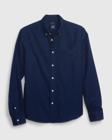
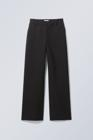
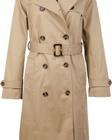
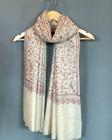
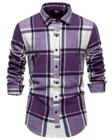
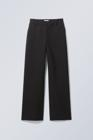
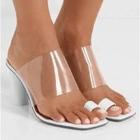
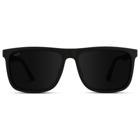
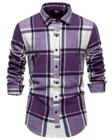
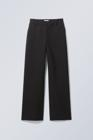
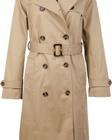
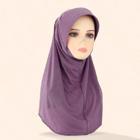
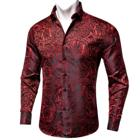
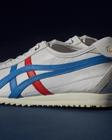
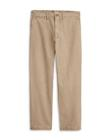
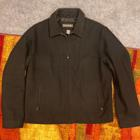
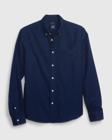
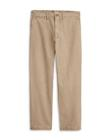
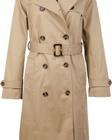
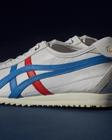
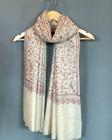
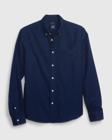
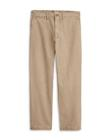
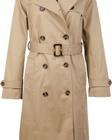
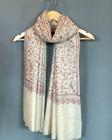
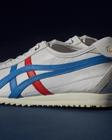
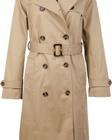
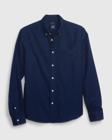
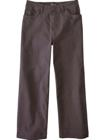
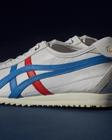
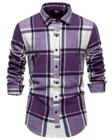
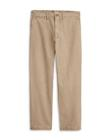
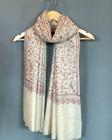
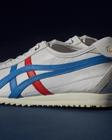
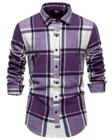
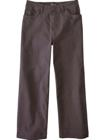
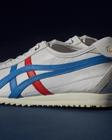
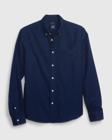
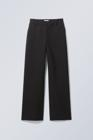
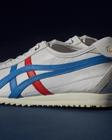
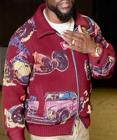
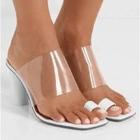
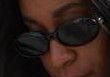
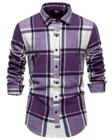
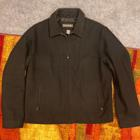
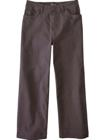
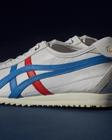
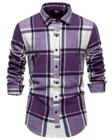
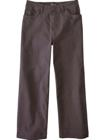
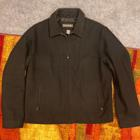
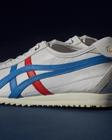
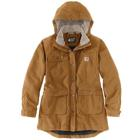
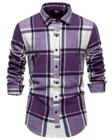
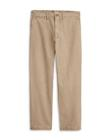
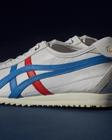
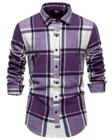
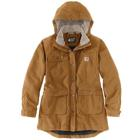
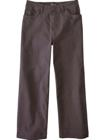
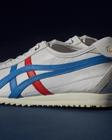
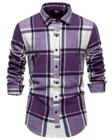
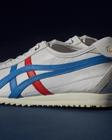
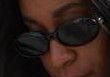
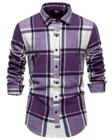
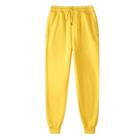
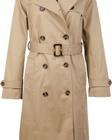
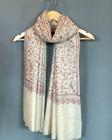
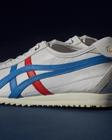
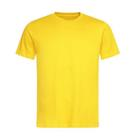
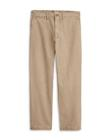
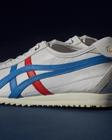
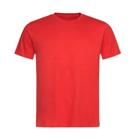
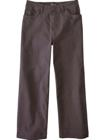
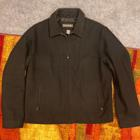
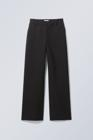
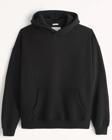
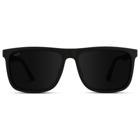
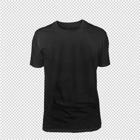
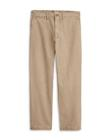
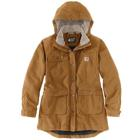
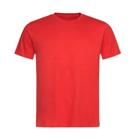
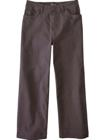
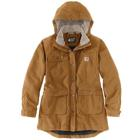
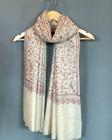
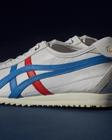
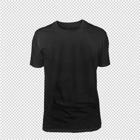
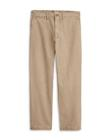
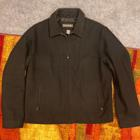
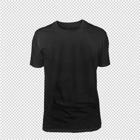
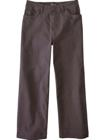
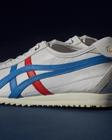
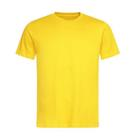
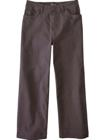
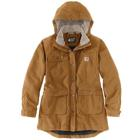
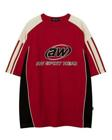
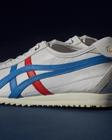
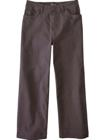
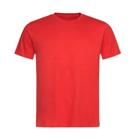
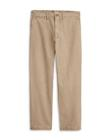
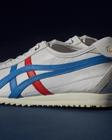
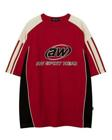
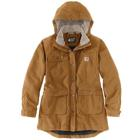
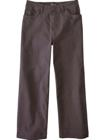
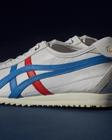
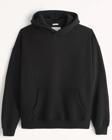
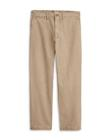
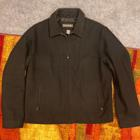
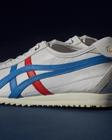
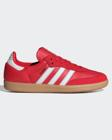
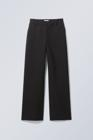
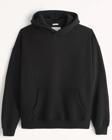
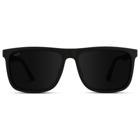
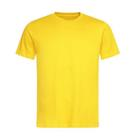
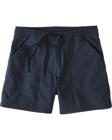
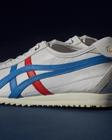
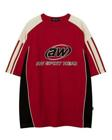
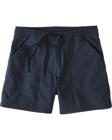
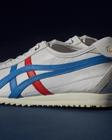
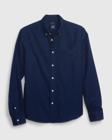
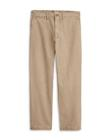
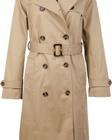
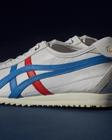
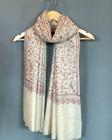
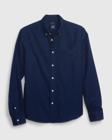
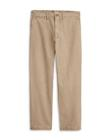
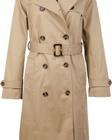
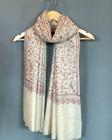
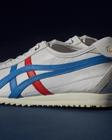
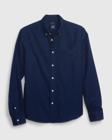
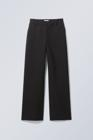
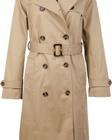
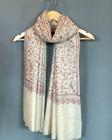
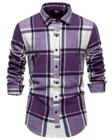
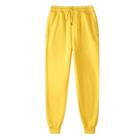
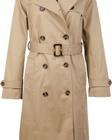
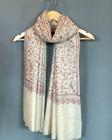
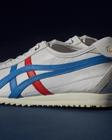
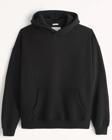
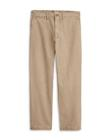
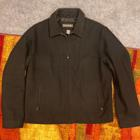
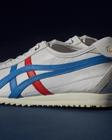
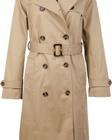
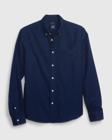
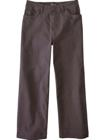
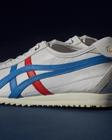
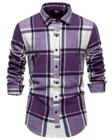
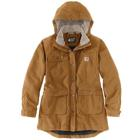
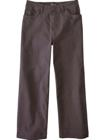
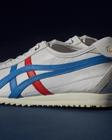
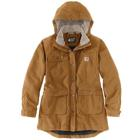
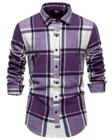
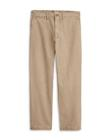
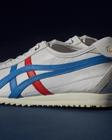
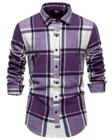
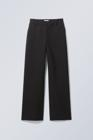
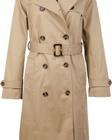
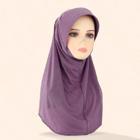
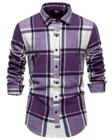
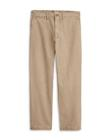
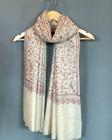
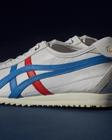
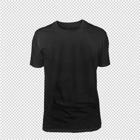
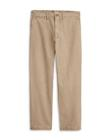
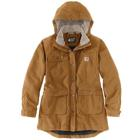
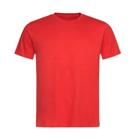
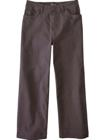
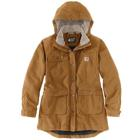
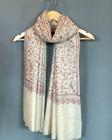
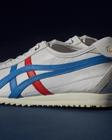
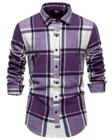
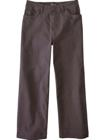
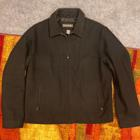
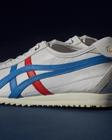
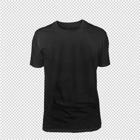
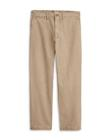
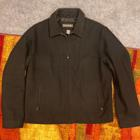
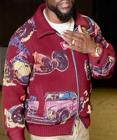
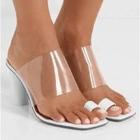
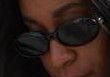
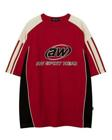
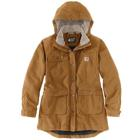
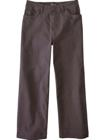
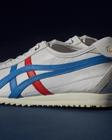
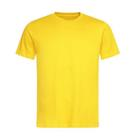
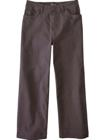
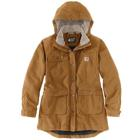
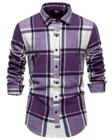
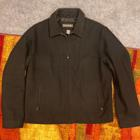
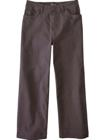
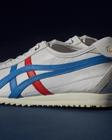
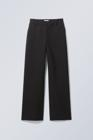
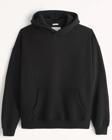
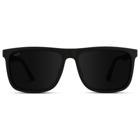
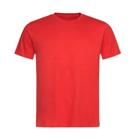
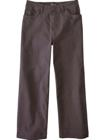
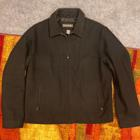
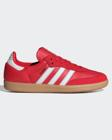
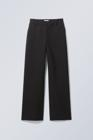
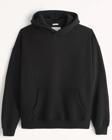
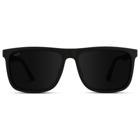
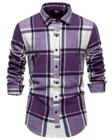
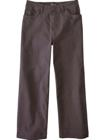
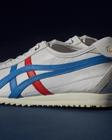
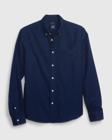
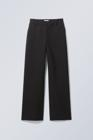
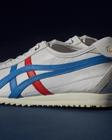
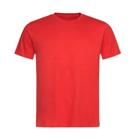
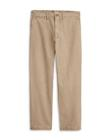
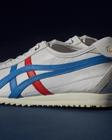
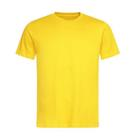
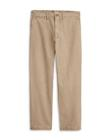
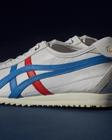
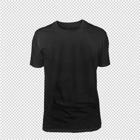
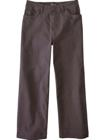
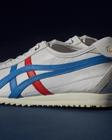
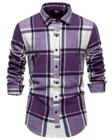
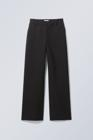
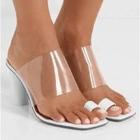
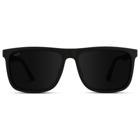
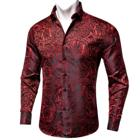
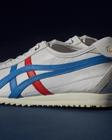
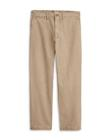
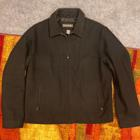
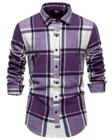
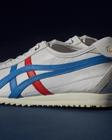
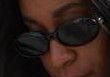
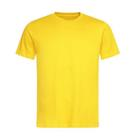
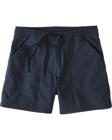
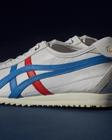
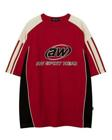
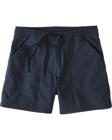
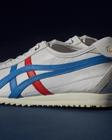
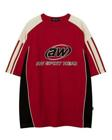
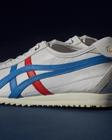
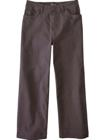
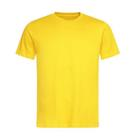
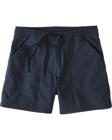
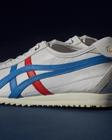
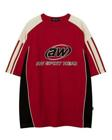
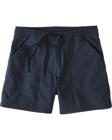
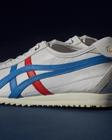
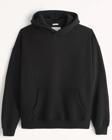
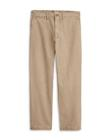
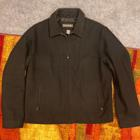
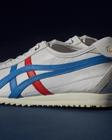
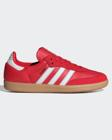
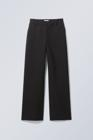
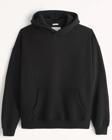
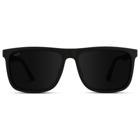
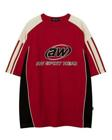
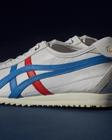
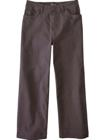
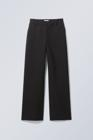
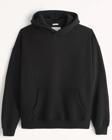
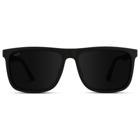
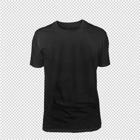
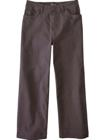
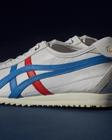
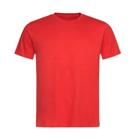
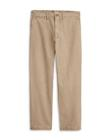
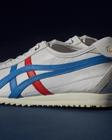
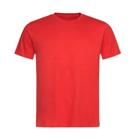
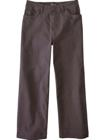
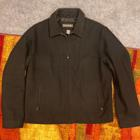
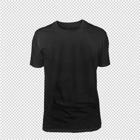
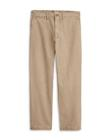
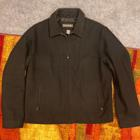
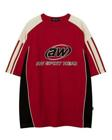
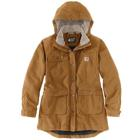
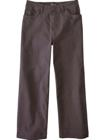
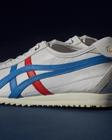
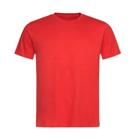
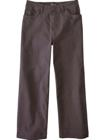
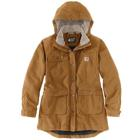
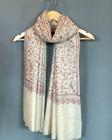
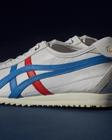
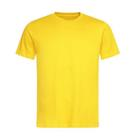
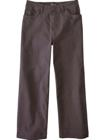
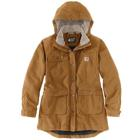
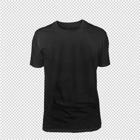
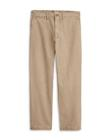
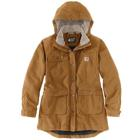
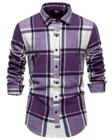
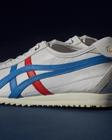
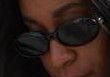
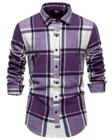
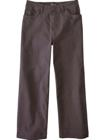
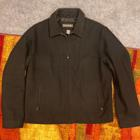
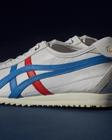
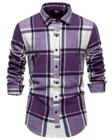
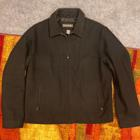
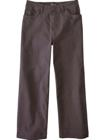
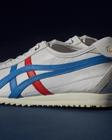
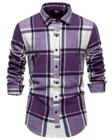
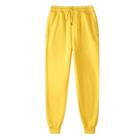
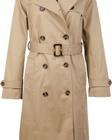
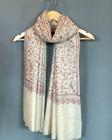
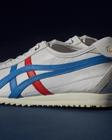
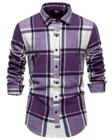
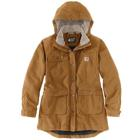
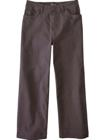
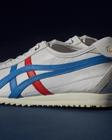
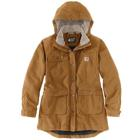
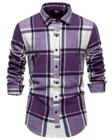
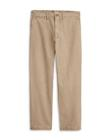
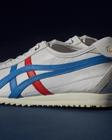
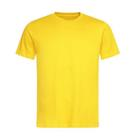
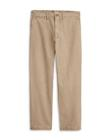
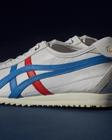
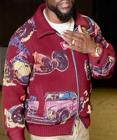
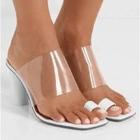
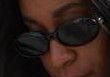
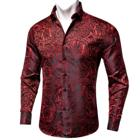
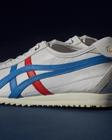
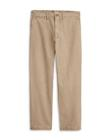
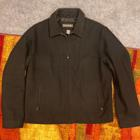
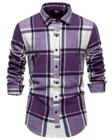
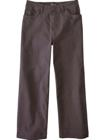
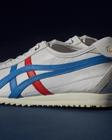
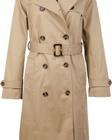
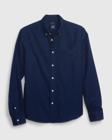
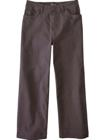
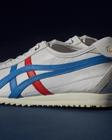
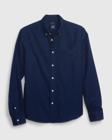
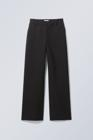
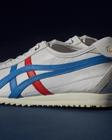
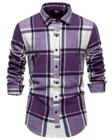
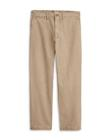
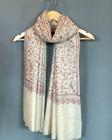
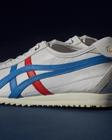
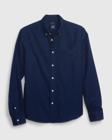
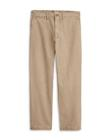
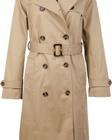
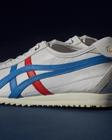
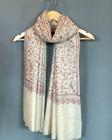
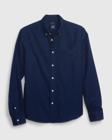
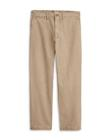
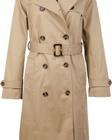
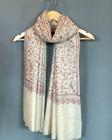
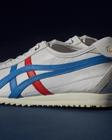
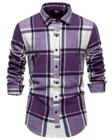
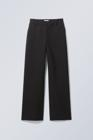
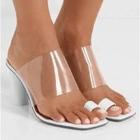
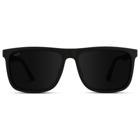
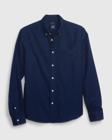
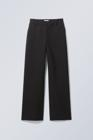
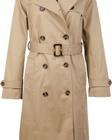
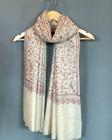
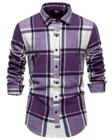
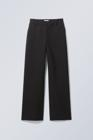
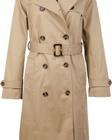
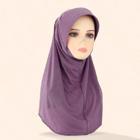
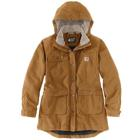
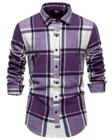
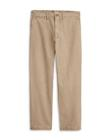
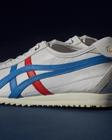
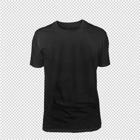
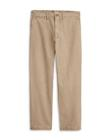
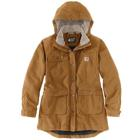
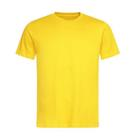
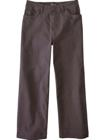
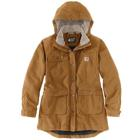
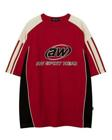
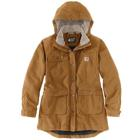
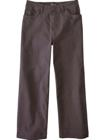
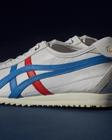
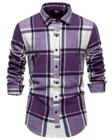
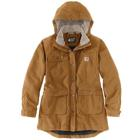
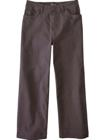
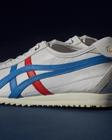
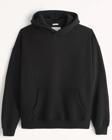
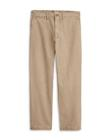
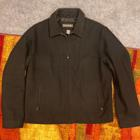
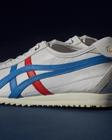
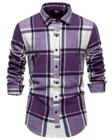
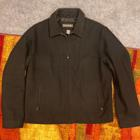
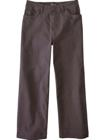
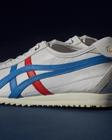
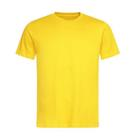
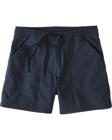
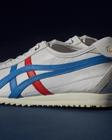
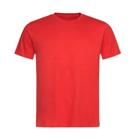
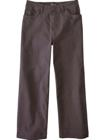
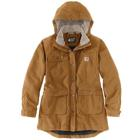
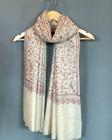
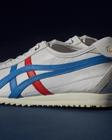
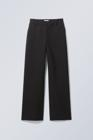
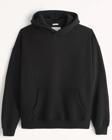
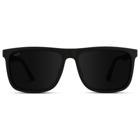
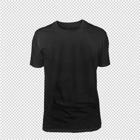
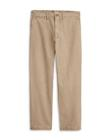
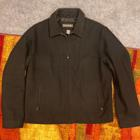
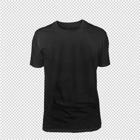
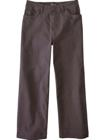
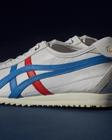
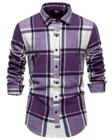
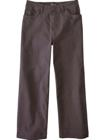
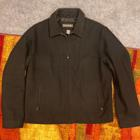
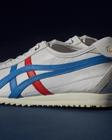
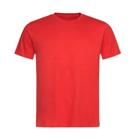
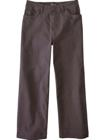
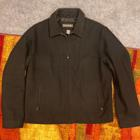
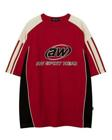
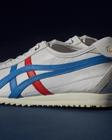
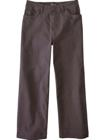
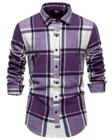
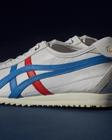
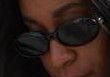
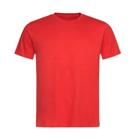
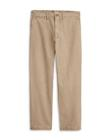
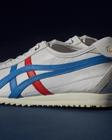
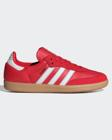
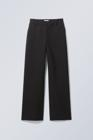
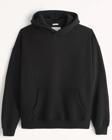
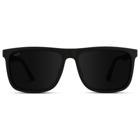
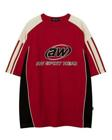
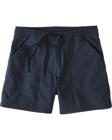
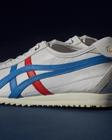
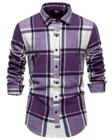
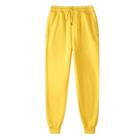
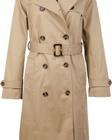
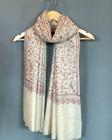
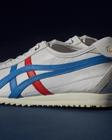
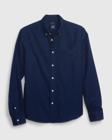
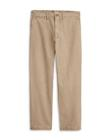
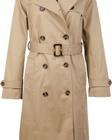
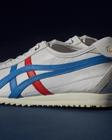
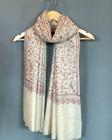
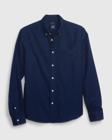
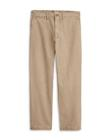
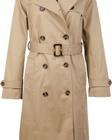
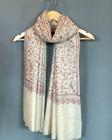
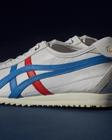
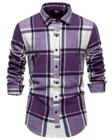
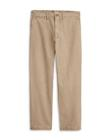
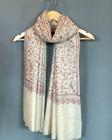
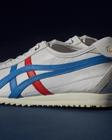
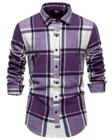
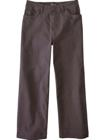
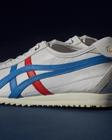
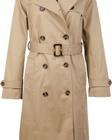
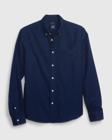
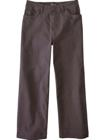
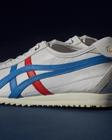
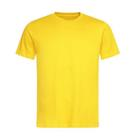
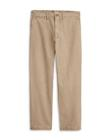
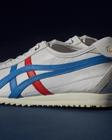
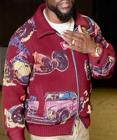
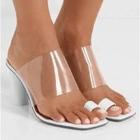
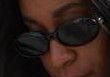
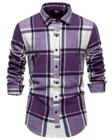
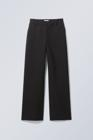
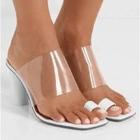
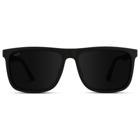
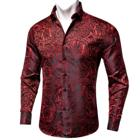
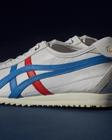
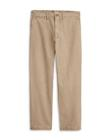
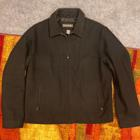
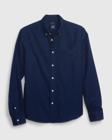
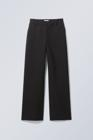
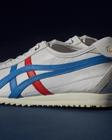
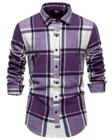
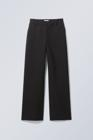
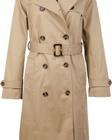
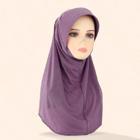
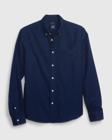
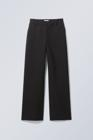
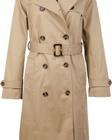
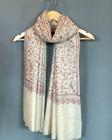

In [12]:
CONFIDENCE_THRESHOLD = 0.5

def render_collection_block(coll: dict) -> str:
    rows = df[(df["collection_key"] == coll["key"]) & (df["noul"].notna())].sort_values("noul", ascending=False)
    accepted = rows[rows["noul"] >= CONFIDENCE_THRESHOLD]
    rejected = rows[rows["noul"] < CONFIDENCE_THRESHOLD]

    parts = []
    parts.append(f"<h3 style='margin-top:24px'>{coll['name']}</h3>")
    parts.append(f"<div style='color:#666;font-size:12px;max-width:640px'>{coll['description']}</div>")
    parts.append(f"<div style='margin:8px 0;font-weight:bold'>Accepted (noul ≥ {CONFIDENCE_THRESHOLD}) — {len(accepted)}</div>")
    for _, r in accepted.iterrows():
        outfit = next((o for o in outfits if o["id"] == r["outfit_id"]), None)
        if not outfit:
            continue
        bar = int(round(float(r["noul"]) * 100))
        parts.append(
            f"<div style='display:flex;align-items:center;margin:6px 0;padding:6px;border:1px solid #eee;border-radius:6px'>"
            f"<div style='width:180px;font-size:13px'>"
            f"  <div style='font-weight:600'>{r['outfit_name']}</div>"
            f"  <div style='color:#0a7f42;font-family:monospace'>{float(r['noul']):.3f}</div>"
            f"  <div style='background:#e5e5e5;height:6px;border-radius:3px;margin-top:4px'>"
            f"    <div style='background:#0a7f42;height:6px;width:{bar}%;border-radius:3px'></div>"
            f"  </div>"
            f"</div>"
            f"<div style='flex:1'>{outfit_image_html(outfit)}</div>"
            f"</div>"
        )
    parts.append(f"<details style='margin:8px 0'><summary style='cursor:pointer;color:#666'>Rejected ({len(rejected)})</summary>")
    for _, r in rejected.iterrows():
        outfit = next((o for o in outfits if o["id"] == r["outfit_id"]), None)
        if not outfit:
            continue
        parts.append(
            f"<div style='display:flex;align-items:center;margin:4px 0;padding:4px;opacity:0.6'>"
            f"<div style='width:180px;font-size:12px'>{r['outfit_name']} <span style='color:#c00;font-family:monospace'>{float(r['noul']):.3f}</span></div>"
            f"<div style='flex:1'>{outfit_image_html(outfit)}</div>"
            f"</div>"
        )
    parts.append("</details>")
    return "".join(parts)


full_html_parts = [
    "<h2>Prototype 23 — Jev collection auto-assignment</h2>",
    f"<div style='color:#666'>Closet: {len(outfits)} outfits, {len(items)} items. Targets: {len(TARGET_COLLECTIONS)} collections. Jev calls: {sum(1 for m in run_meta if m['ok'])}/{len(run_meta)}.</div>",
]
for coll in TARGET_COLLECTIONS:
    full_html_parts.append(render_collection_block(coll))

full_html = "".join(full_html_parts)
display(HTML(full_html))

## 10. Save artefacts

- `outputs/23/noul_results.csv` — per-(collection, outfit) Noul + raw answer.
- `outputs/23/run_meta.csv` — per-call latency + usage.
- `outputs/23/summary.csv` — per-collection roll-up (also displayed above).
- `outputs/23/report.html` — self-contained visual review (images embedded as data-URLs).


In [13]:
# CSVs
df_out = df.copy()
df_out.to_csv(OUT_DIR / "noul_results.csv", index=False)
pd.DataFrame(run_meta).to_csv(OUT_DIR / "run_meta.csv", index=False)
summary_df.to_csv(OUT_DIR / "summary.csv", index=False)

# Report HTML — same string that was displayed inline, dumped standalone
(OUT_DIR / "report.html").write_text(
    "<!doctype html><html><head><meta charset='utf-8'><title>Prototype 23</title>"
    "<style>body{font-family:system-ui,-apple-system,sans-serif;padding:24px;max-width:960px;margin:auto}</style>"
    f"</head><body>{full_html}</body></html>"
)

print("Saved:")
for f in sorted(OUT_DIR.iterdir()):
    print(f"  {f.relative_to(REPO_ROOT)}")

Saved:
  prototypes/outputs/23/noul_results.csv
  prototypes/outputs/23/report.html
  prototypes/outputs/23/run_meta.csv
  prototypes/outputs/23/summary.csv


## 11. Interpretation cheatsheet

Read these numbers before deciding on Phase 3 scope:

- **Median Noul per collection.** Should be well-separated across collections — an outfit named *Sophisticated Professional* should score high on Workwear Rotation and low on Outdoor Rugged. If everything hovers near 0.5, the collection descriptions are too vague OR item metadata is too thin — enrich item descriptors (Phase 1.5) before shipping.
- **`n_noul_ge_0.7` per collection.** This is the count of confident assignments. If it's 0, no user-facing suggestion is safe to auto-generate. If it's 5-10 per collection, the UX is a batched "add these to *Workwear Rotation*?" card.
- **Per-Noul amortized latency (ms).** The user-facing latency budget for a cron reconciler is generous, but for an on-outfit-save trigger you want the per-Noul cost under ~30ms. Batching 32 outfits per call already amortizes ~90% of the HTTP overhead — expect ~10-40ms per Noul.
- **Total cost per user for a full rebuild.** If ~$0.001 for 4 collections × 32 outfits, then a heavy user with 20 collections × 100 outfits is ~$0.03/rebuild — cron-daily = ~$0.90/user/month. Verify the estimate reflects real usage caps before Phase 3 lands.

Cross-check against existing assignments (Section 8b) — every outfit already in a DB collection should score ≥ 0.5 against at least one target collection. If some don't, the outfit's descriptor is thin (item names, no `ai_description`, no `wear_context`) → same Phase 1.5 signal.
